# Ejercicio: Construcción de un espacio de búsqueda
## Fundamentos de Inteligencia Artificial

**Integrantes:**
- HANNIEL OLVERA MATA
- FERNANDO JIMENEZ ANGELES

**Problema:** un robot de reparto debe llevar una pieza desde **Recepción** hasta **Embarque**. El robot solo puede moverse entre zonas que están conectadas directamente.

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

## Parte 1. Representación en Python

En el diccionario grafo_original, cada zona (estado) tiene una lista con las zonas a las que se puede mover directamente. Las conexiones van en los dos sentidos, igual que en el ejemplo de la práctica anterior.

In [ ]:
grafo_original = {
    "Recepción": ["Pasillo A", "Pasillo B"],
    "Pasillo A": ["Recepción", "Almacén 1"],
    "Pasillo B": ["Recepción", "Almacén 1", "Almacén 2"],
    "Almacén 1": ["Pasillo A", "Pasillo B", "Inspección"],
    "Almacén 2": ["Pasillo B", "Ensamble"],
    "Inspección": ["Almacén 1", "Ensamble", "Calidad"],
    "Ensamble": ["Almacén 2", "Inspección", "Calidad"],
    "Calidad": ["Inspección", "Ensamble", "Empaque"],
    "Empaque": ["Calidad", "Embarque"],
    "Embarque": ["Empaque"]
}

inicio = "Recepción"
meta = "Embarque"

print("Estado inicial:", inicio)
print("Estado meta:", meta)
print("Estados:", list(grafo_original.keys()))

Estado inicial: Recepción
Estado meta: Embarque
Estados: ['Recepción', 'Pasillo A', 'Pasillo B', 'Almacén 1', 'Almacén 2', 'Inspección', 'Ensamble', 'Calidad', 'Empaque', 'Embarque']


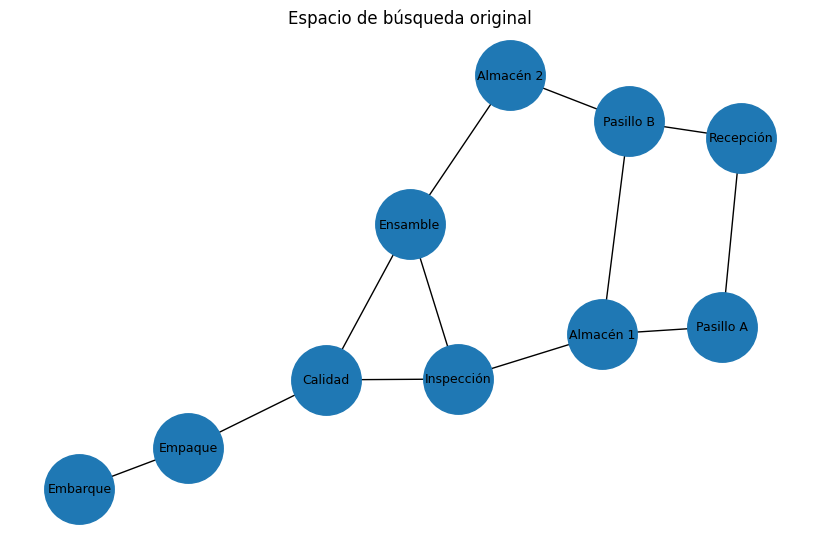

In [ ]:
G = nx.Graph()

for estado, vecinos in grafo_original.items():
    G.add_node(estado)
    for vecino in vecinos:
        G.add_edge(estado, vecino)

plt.figure(figsize=(8, 5))
nx.draw(G, with_labels=True, node_size=2500, font_size=9)
plt.title("Espacio de búsqueda original")
plt.show()

## Parte 2. Primera modificación

Se detecta una fuga en **Almacén 1**. La zona sigue existiendo, pero no puede usarse. Por eso Almacén 1 se queda como estado, pero sin conexiones: su lista queda vacía y se quita de las listas de las demás zonas.

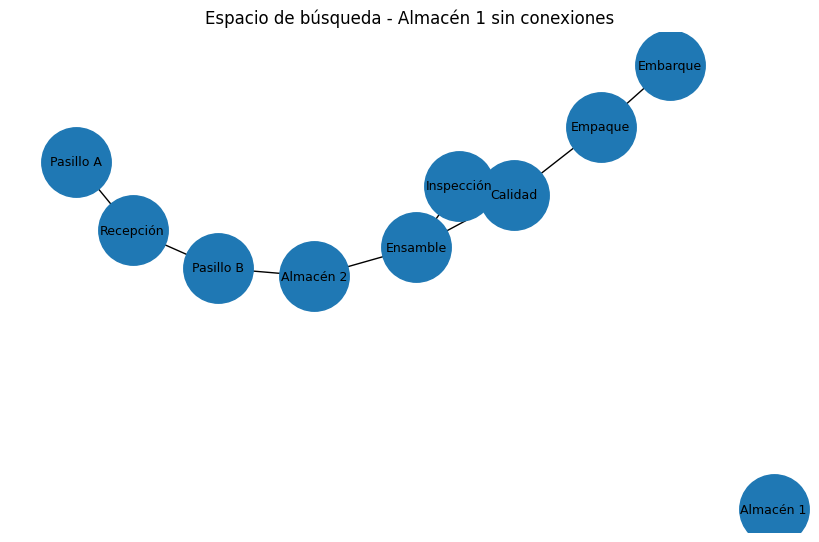

In [ ]:
grafo_modificado_1 = {
    "Recepción": ["Pasillo A", "Pasillo B"],
    "Pasillo A": ["Recepción"],
    "Pasillo B": ["Recepción", "Almacén 2"],
    "Almacén 1": [],
    "Almacén 2": ["Pasillo B", "Ensamble"],
    "Inspección": ["Ensamble", "Calidad"],
    "Ensamble": ["Almacén 2", "Inspección", "Calidad"],
    "Calidad": ["Inspección", "Ensamble", "Empaque"],
    "Empaque": ["Calidad", "Embarque"],
    "Embarque": ["Empaque"]
}

G1 = nx.Graph()

for estado, vecinos in grafo_modificado_1.items():
    G1.add_node(estado)
    for vecino in vecinos:
        G1.add_edge(estado, vecino)

plt.figure(figsize=(8, 5))
nx.draw(G1, with_labels=True, node_size=2500, font_size=9)
plt.title("Espacio de búsqueda - Almacén 1 sin conexiones")
plt.show()

### Respuestas - Parte 2

1. **Modifica el grafo:** en grafo_modificado_1, Almacén 1 quedó con lista vacía y se quitó de las listas de Pasillo A, Pasillo B e Inspección.
2. **Visualización:** se dibujó arriba. Almacén 1 sigue apareciendo como nodo, pero sin ninguna línea que lo una con otra zona.
3. **¿Todavía existe al menos un camino entre Recepción y Embarque?** Sí.
4. **Un posible camino:** Recepción → Pasillo B → Almacén 2 → Ensamble → Calidad → Empaque → Embarque

## Parte 3. Segunda modificación

Además de la fuga en Almacén 1, ahora queda bloqueada la conexión directa entre **Ensamble** y **Calidad**. Se quita Calidad de la lista de Ensamble y Ensamble de la lista de Calidad.

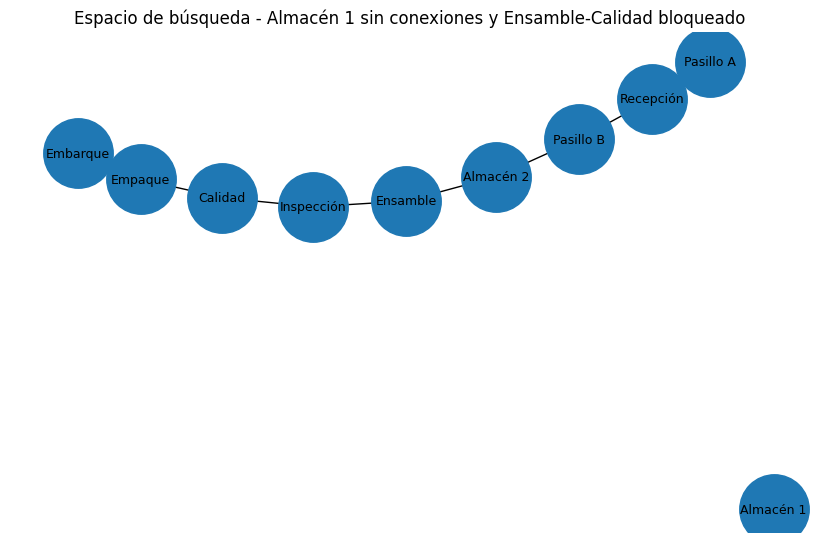

In [ ]:
grafo_modificado_2 = {
    "Recepción": ["Pasillo A", "Pasillo B"],
    "Pasillo A": ["Recepción"],
    "Pasillo B": ["Recepción", "Almacén 2"],
    "Almacén 1": [],
    "Almacén 2": ["Pasillo B", "Ensamble"],
    "Inspección": ["Ensamble", "Calidad"],
    "Ensamble": ["Almacén 2", "Inspección"],
    "Calidad": ["Inspección", "Empaque"],
    "Empaque": ["Calidad", "Embarque"],
    "Embarque": ["Empaque"]
}

G2 = nx.Graph()

for estado, vecinos in grafo_modificado_2.items():
    G2.add_node(estado)
    for vecino in vecinos:
        G2.add_edge(estado, vecino)

plt.figure(figsize=(8, 5))
nx.draw(G2, with_labels=True, node_size=2500, font_size=9)
plt.title("Espacio de búsqueda - Almacén 1 sin conexiones y Ensamble-Calidad bloqueado")
plt.show()

### Respuestas - Parte 3

1. Modifica nuevamente el grafo: en grafo_modificado_2, Almacén 1 sigue sin conexiones y además Ensamble y Calidad ya no aparecen en la lista del otro.
2. Visualización: se dibujó arriba. Ya no hay línea directa entre Ensamble y Calidad.
3. ¿Sigue siendo posible llegar desde Recepción hasta Embarque? Sí.
4. Un posible camino: Recepción → Pasillo B → Almacén 2 → Ensamble → Inspección → Calidad → Empaque → Embarque. Aunque se bloqueó la conexión directa, Inspección está conectada con Ensamble y con Calidad, así que sirve como camino alterno.
5. ¿Qué cambió en el espacio de búsqueda? Con las restricciones desaparecieron conexiones, y por eso desaparecieron caminos. Al inicio había varios caminos posibles; ahora solo queda uno, y obligatoriamente pasa por Inspección. Pasillo A también quedó como un camino sin salida, porque solo se conecta con Recepción.

## Parte 4. Reflexión final

1. ¿Cuál es la diferencia entre definir un problema de búsqueda y construir su espacio de búsqueda?
   Definir el problema es decir qué se quiere resolver: cuál es el estado inicial (Recepción), cuál es la meta (Embarque) y qué movimientos están permitidos. Construir el espacio de búsqueda es dibujar o representar en el programa todas las zonas y todas las conexiones, es decir, el grafo completo.

2. ¿El espacio de búsqueda representa una solución o representa todas las posibilidades disponibles?
   Representa todas las posibilidades disponibles. No es la solución: es el mapa donde están los caminos que llegan a la meta y también los que no llegan a ningún lado, como Pasillo A en la Parte 3.

3. Si una persona observa el grafo, puede proponer rápidamente un camino. ¿Qué necesitaría la computadora para recorrerlo de manera sistemática?
   La computadora no "ve" el dibujo como una persona. Necesitaría una forma ordenada de recorrer el grafo, es decir, un algoritmo de búsqueda como los que veremos más adelante (BFS o DFS). También necesitaría llevar un registro de qué zonas ya visitó para no dar vueltas en círculo, y saber qué zonas le faltan por revisar.